# Postcode-level estimation of school-run car use (Leeds) – pipeline walkthrough

Team 9 · client: Hastings Direct.

This notebook runs the whole analysis, stage by stage, with the same scripts as the command line (`src/*.py`). Each stage:

1. writes its outputs to `outputs/` and its figures to `figures/`;
2. writes its full printed log to `outputs/stageN_log.txt`;
3. shows its key results here.

**Rules followed throughout**

- The 2025 survey and the 2024 cut-off distances are **validation only**.
- Religion is never a predictor.
- Postcodes are strings, distances are in metres, and the school ID is `EstablishmentNumber`.
- All random seeds are 42.

*Generated by `src/build_notebook.py`; edit that file, not this notebook.*

In [1]:
import contextlib, runpy, subprocess, sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT, FIG = ROOT / "outputs", ROOT / "figures"
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)


def run_stage(script, log=None):
    """Run src/<script> exactly as from the command line; save its printout."""
    path = ROOT / "src" / script
    if log is None:
        with contextlib.redirect_stdout(None):
            runpy.run_path(str(path), run_name="__main__")
    else:
        with open(OUT / log, "w") as f, contextlib.redirect_stdout(f):
            runpy.run_path(str(path), run_name="__main__")
    print(f"ran {script}" + (f" -> outputs/{log}" if log else ""))


def show_log(log, start, n=15):
    """Print n lines of a stage log, starting at the first line that contains `start`."""
    lines = (OUT / log).read_text().splitlines()
    i = next(k for k, line in enumerate(lines) if start in line)
    print("\n".join(lines[i:i + n]))

## Stage 1 – Data preparation → `postcodes_master.csv`

- **Primary age** means Reception to Year 6 on Census day: 1/12 of the 0–4 band, all of 5–9 and 19/60 of 10–14.
- **Car access** means 1 or more cars: `car_rate = 1 − no car / table total`.
- Each OA's children and households are split **equally** between its postcodes. Giving every postcode the full OA count would inflate the total about 8 times.

In [2]:
run_stage("stage1_data_prep.py", "stage1_log.txt")
m = pd.read_csv(OUT / "postcodes_master.csv", dtype={"POSTCODE": str, "OA": str})
assert m["POSTCODE"].is_unique and m["POSTCODE"].notna().all()
print(f"{len(m):,} postcodes, {m.OA.nunique():,} OAs, {m.est_kids.sum():,.1f} primary-age children")
m.head()

ran stage1_data_prep.py -> outputs/stage1_log.txt
20,799 postcodes, 2,606 OAs, 68,784.9 primary-age children


,POSTCODE,OA,X,Y,households,car_rate,est_kids
0,WF10 2AA,E00056960,443311.0,428399.0,7.364,0.913,1.020
1,WF10 2AB,E00056960,443376.0,428722.0,7.364,0.913,1.020
2,WF10 2AE,E00170567,442573.0,427107.0,11.308,0.939,4.265
3,WF10 2AF,E00056989,441325.0,428401.0,10.500,0.776,1.887
4,WF10 2AG,E00170565,442073.0,427789.0,20.667,0.925,8.209


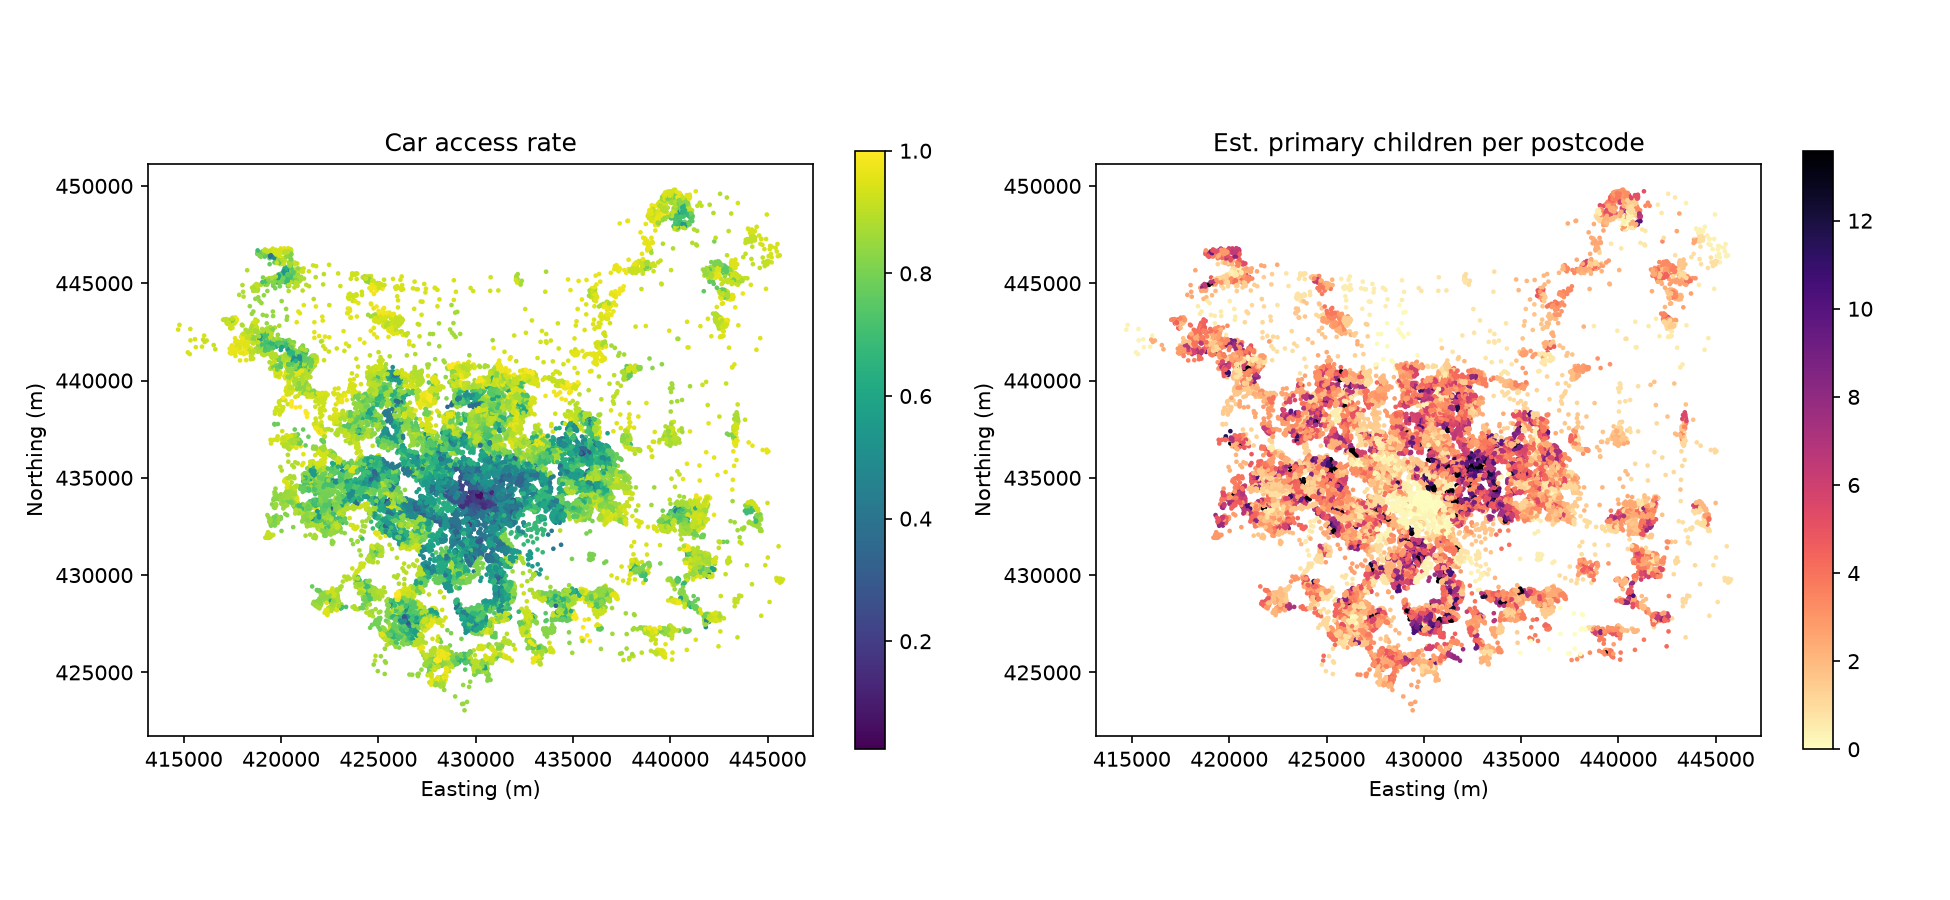

In [3]:
display(Image(FIG / "stage1_maps.png", width=900))

## Stage 2 – Distances and Method 1 (nearest school)

The distance matrix is straight-line metres from OS grid coordinates, computed with NumPy broadcasting (20,799 × 225). Method 1 sends every child to the nearest listed school.

In [4]:
run_stage("stage2_distances_method1.py", "stage2_log.txt")
m1 = pd.read_csv(OUT / "method1_postcode.csv", dtype={"POSTCODE": str})
m1["dist_nearest_m"].describe(percentiles=[.5, .9]).round(0)

ran stage2_distances_method1.py -> outputs/stage2_log.txt


count    20799.0
mean       501.0
std        346.0
min          0.0
50%        425.0
90%        904.0
max       3612.0
Name: dist_nearest_m, dtype: float64

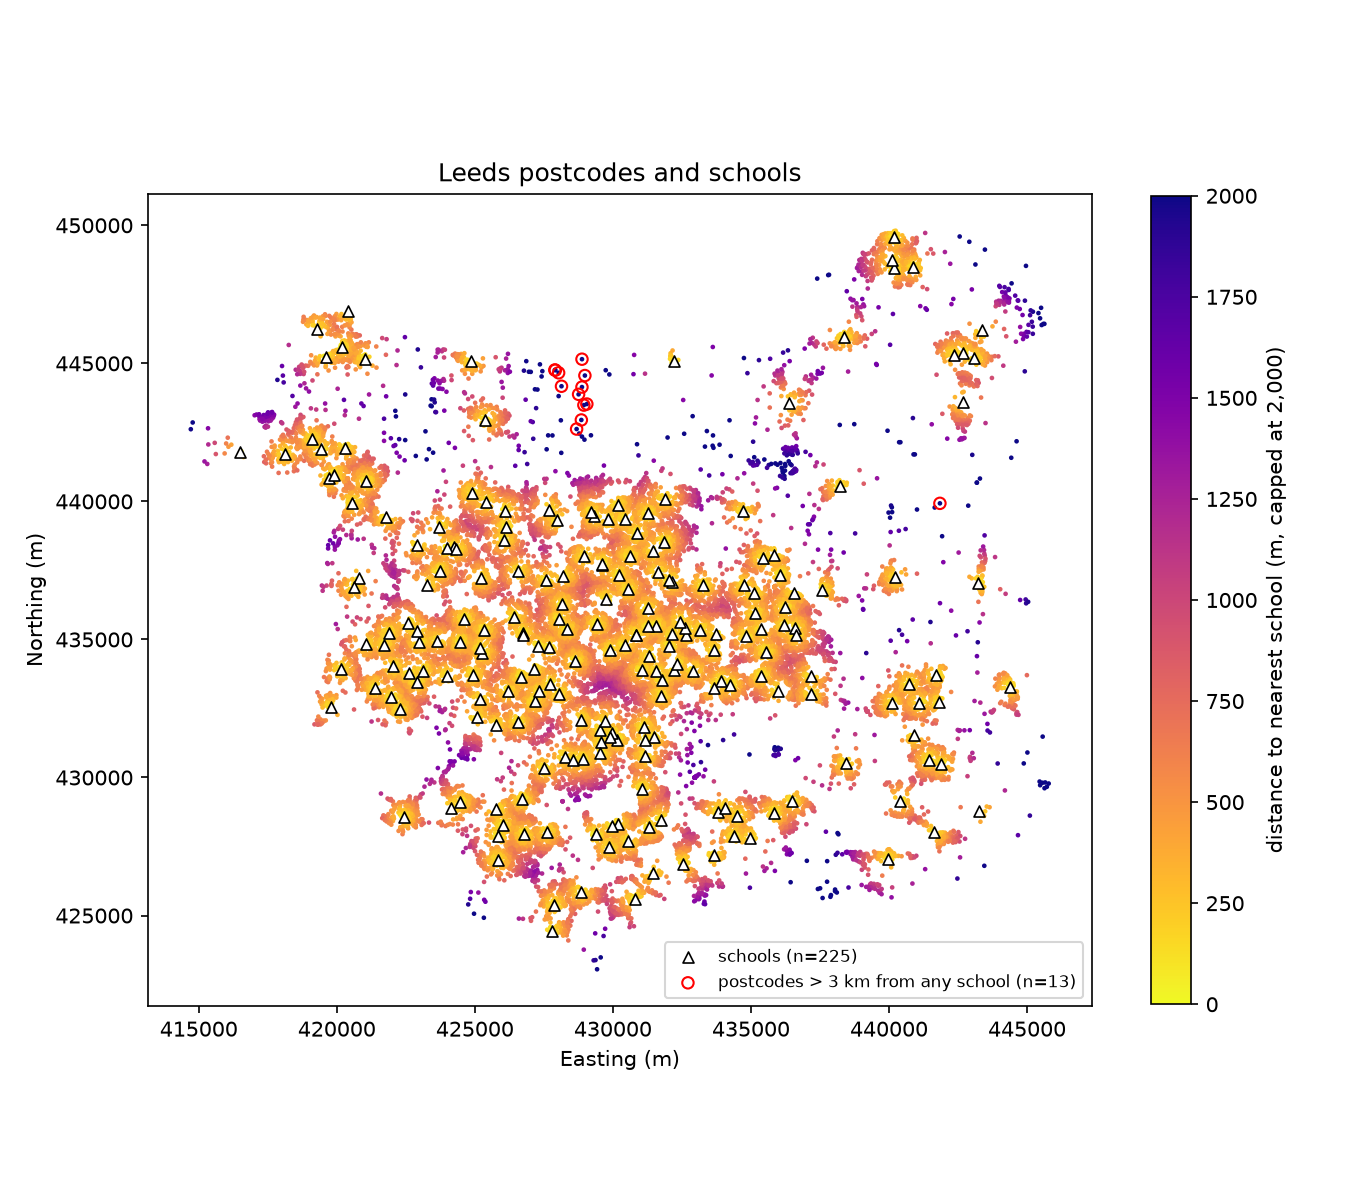

In [5]:
display(Image(FIG / "stage2_map.png", width=700))

## Stage 3 – Method 2: probabilistic attendance and car use

P(j | i) ∝ capacity_j · B_j · exp(−d_ij / λ), with balancing factors B_j ≤ 1 that enforce school capacity. Then P(car | i, j) = car_rate_i · g(d_ij), where g is a logistic curve with d50 = 1,000 m fixed a priori.

λ is chosen on **input data only**: the value under which population and distance best reproduce the real school rolls. A 2-fold school split checks that the choice holds out of sample.

In [6]:
run_stage("stage3_method2.py", "stage3_log.txt")
display(pd.read_csv(OUT / "method2_ladder.csv").drop(columns="note"))
show_log("stage3_log.txt", "=== Main model outputs", 7)

ran stage3_method2.py -> outputs/stage3_log.txt


,version,corr_with_roll,rmse_vs_roll,schools_over_eff_cap,median_trip_m,car_kids_main,car_share_main,car_kids_baseline
0,M1 nearest school,0.391,159.513,89,382.154,7027.693,0.102,49467.451
1,M2a exp decay only (p=650),0.548,113.314,85,913.302,24207.877,0.352,49467.451
2,M2b exp + capacity weight,0.868,72.097,44,913.898,24241.199,0.352,49467.451
3,M2a power decay only (p=2),0.523,116.475,83,1026.397,27129.726,0.394,49467.451
4,M2b power + capacity weight,0.864,78.807,31,1037.903,27335.106,0.397,49467.451
5,M2c exp + capacity weight + cap (MAIN),0.884,66.571,0,917.187,24318.859,0.354,49467.451


=== Main model outputs
row sums: min 1.000000, max 1.000000
est_car_kids (main, g(d) with d50=1000 m): 24,318.9 = 35.4% of children
est_car_kids (baseline g=1, upper bound):     49,467.5 = 71.9%
per-postcode est_car_rate: median 0.338, p10 0.181, p90 0.601
per-school pred_car_share: median 0.359, p10 0.277, p90 0.446
implied catchment p80: median 1730 m, max 3672 m


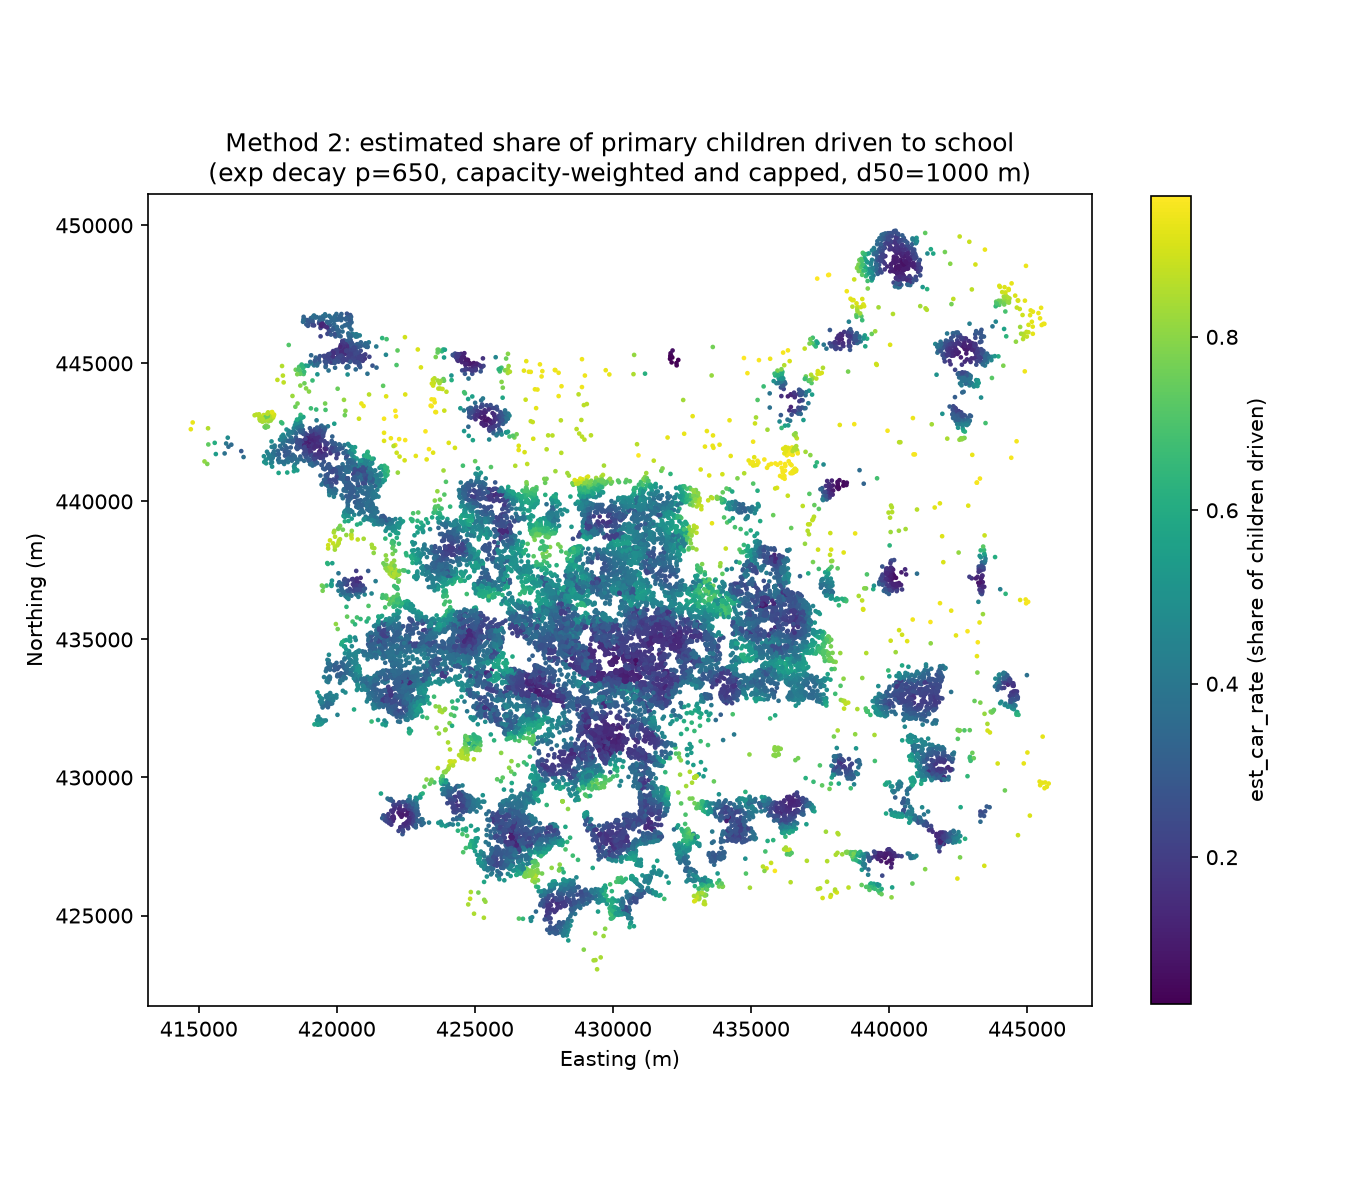

In [7]:
display(Image(FIG / "stage3_map_car_rate.png", width=700))

## Stage 4 – Validation (survey and cut-off distances; never fed back)

Schools are matched to the survey by name in four steps: exact → normalised → fuzzy (score ≥ 95) → manual. The manual decisions are in `data/manual/manual_matches.csv`. The cut-off PDF is matched by DfE number.

In [8]:
run_stage("school_matching.py", "matching_log.txt")
run_stage("stage4_validation.py", "stage4_log.txt")
pd.read_csv(OUT / "validation_metrics_survey.csv").query("subset == 'all compared'")

ran school_matching.py -> outputs/matching_log.txt


ran stage4_validation.py -> outputs/stage4_log.txt


,subset,model,n,pearson,spearman,MAE,RMSE,bias,sd_pred,sd_obs,slope_obs_on_pred
0,all compared,pred_share_M2,194,0.517,0.503,0.124,0.153,-6.889e-03,0.072,0.177,1.271
1,all compared,pred_share_M2_baseline,194,0.528,0.508,0.373,0.402,3.711e-01,0.123,0.177,0.761
2,all compared,pred_share_M1,194,0.447,0.444,0.261,0.302,-2.569e-01,0.089,0.177,0.890
3,all compared,constant = observed mean (reference),194,NaN,NaN,0.143,0.177,3.892e-17,0.000,0.177,NaN


,subset,implied,n,spearman,pearson_log,median_cutoff_m,median_implied_m,median_ratio,share_ratio_0.5_to_2
0,all numeric,catchment_p80_m,77,-0.060,-0.046,1087.917,1763.007,1.432,0.584
1,all numeric,catchment_p95_m,77,0.023,-0.017,1087.917,2872.192,2.629,0.299
2,standard rows only,catchment_p80_m,74,-0.087,-0.066,1076.651,1745.390,1.440,0.595
3,standard rows only,catchment_p95_m,74,-0.013,-0.046,1076.651,2872.032,2.680,0.297


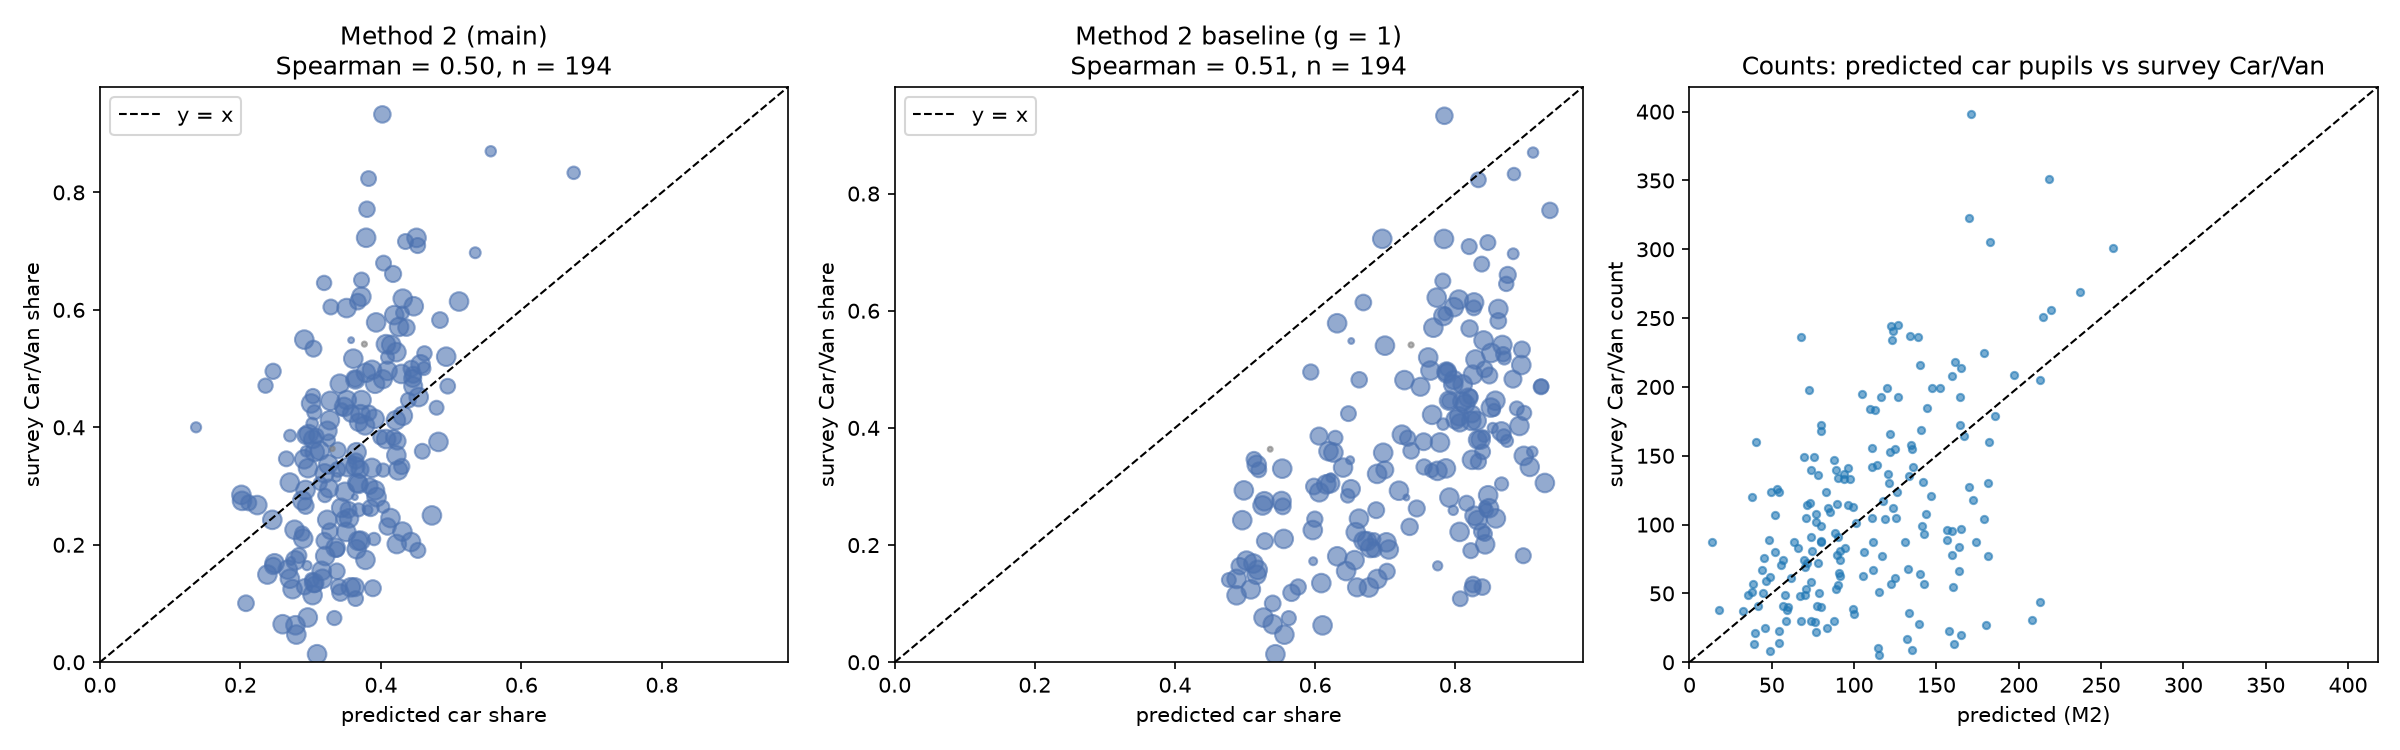

In [9]:
display(pd.read_csv(OUT / "validation_metrics_cutoff.csv"))
display(Image(FIG / "stage4_survey_scatter.png", width=950))

## Stage 5 – Fairness audit

Protected characteristics are used only to **audit** the model. The religion-by-OA file was not provided, so that check is not run; its method is in `outputs/fairness_method.md`.

ran stage5_fairness.py -> outputs/stage5_log.txt


,group,n_schools,obs_share,pred_share,mean_error,ci_low,ci_high
0,Catholic,23,0.522,0.355,-0.167,-0.234,-0.101
1,Church of England,29,0.378,0.377,-0.001,-0.049,0.048
2,No religious designation,142,0.338,0.356,0.018,-0.005,0.039


,term,coef,ci_low,ci_high
0,intercept,4.108e-01,0.313,0.510
1,Catholic,-1.992e-01,-0.258,-0.143
2,Church of England,9.630e-04,-0.044,0.051
3,catchment car rate,-5.347e-01,-0.673,-0.399


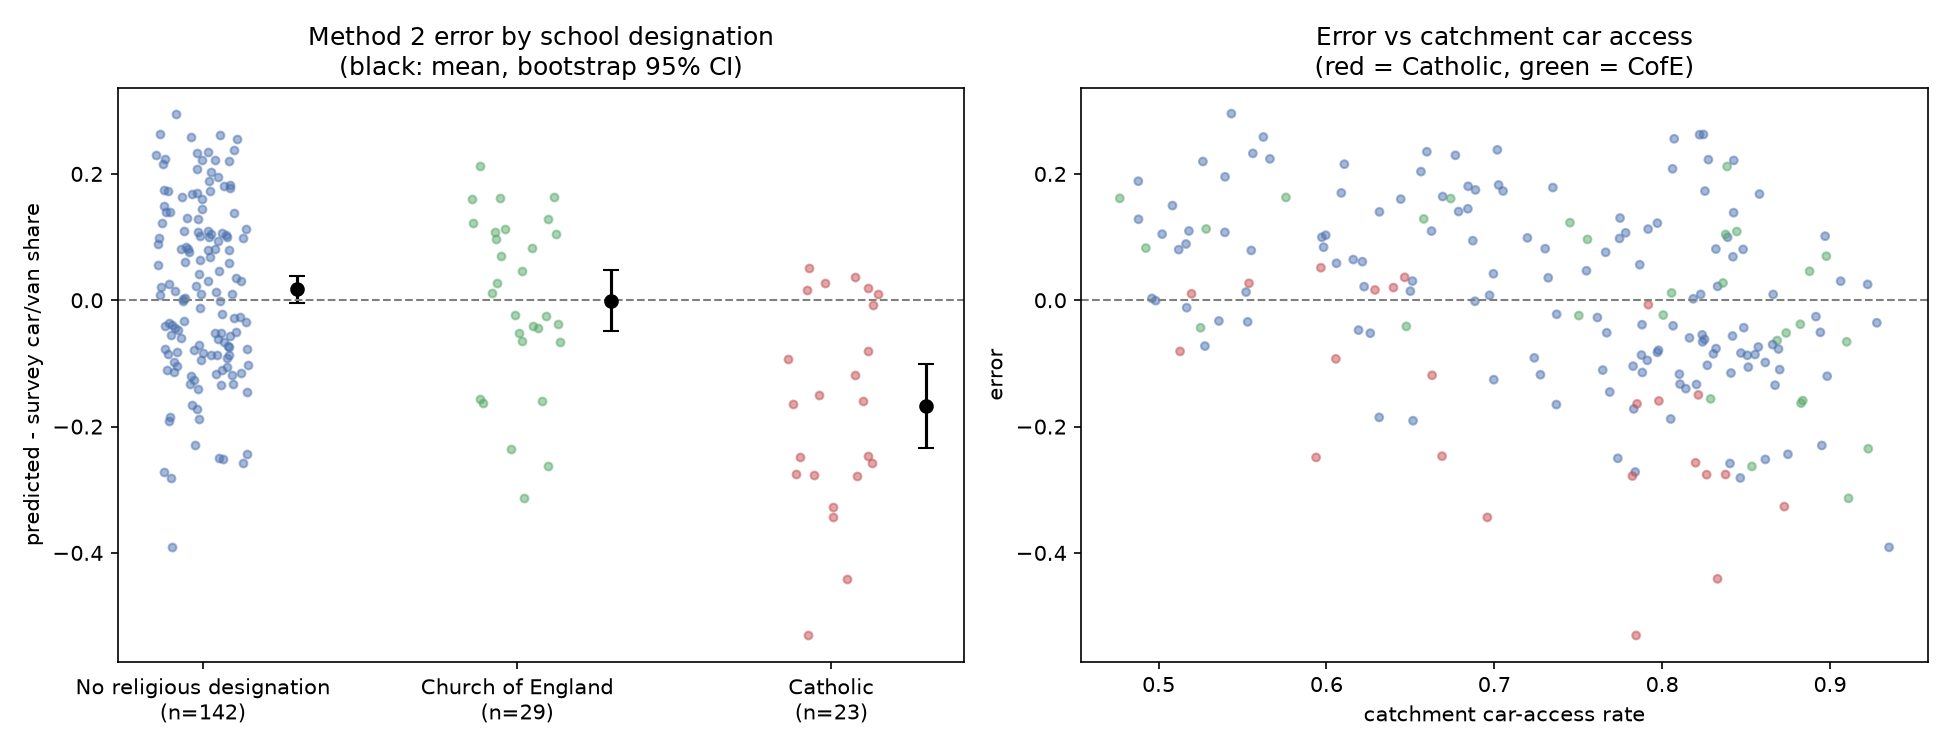

In [10]:
run_stage("stage5_fairness.py", "stage5_log.txt")
display(pd.read_csv(OUT / "fairness_groups.csv")[["group", "n_schools", "obs_share", "pred_share",
                                                     "mean_error", "ci_low", "ci_high"]])
display(pd.read_csv(OUT / "fairness_regression.csv"))
display(Image(FIG / "stage5_error_by_group.png", width=950))

## Stage 6 – Sensitivity and uncertainty

The scenarios change one assumption at a time. A Monte Carlo run then draws λ, d50 and the g(d) scale jointly (200 draws, seed 42).

In [11]:
run_stage("stage6_sensitivity.py", "stage6_log.txt")
display(pd.read_csv(OUT / "sensitivity_one_at_a_time.csv"))
show_log("stage6_log.txt", "=== B. Monte Carlo", 12)

ran stage6_sensitivity.py -> outputs/stage6_log.txt


,assumption,value,car_kids,car_share,spearman_vs_main,top10_overlap,median_abs_change_pp,survey_spearman_REPORT_ONLY
0,main,-,24318.859,0.354,1.000,1.000,0.000,0.503
1,decay lambda (m),325,14205.170,0.207,0.898,0.880,13.966,0.608
2,decay lambda (m),1300,35809.367,0.521,0.893,0.849,15.231,0.422
3,decay form,power beta=2,27351.333,0.398,0.906,0.900,5.826,0.415
4,g(d) midpoint d50 (m),500,36471.124,0.530,0.929,0.882,16.929,0.592
5,g(d) midpoint d50 (m),2000,8390.451,0.122,0.840,0.762,22.152,0.228
6,g(d) steepness scale (m),125,23309.011,0.339,0.985,0.962,1.862,0.441
7,g(d) steepness scale (m),500,25504.602,0.371,0.974,0.952,2.524,0.579
8,route detour factor,1.3,25615.288,0.372,0.961,0.909,3.090,0.574
9,capacity weight A_j,off (A=1),24299.901,0.353,0.986,0.960,0.884,0.491


=== B. Monte Carlo, 200 joint draws (seed 42); ranges {'lambda': (325.0, 1300.0), 'd50': (500.0, 2000.0), 'scale': (150.0, 400.0)}
citywide car-driven children: p5 5463, p50 20358, p95 37213  (share p5 7.9%, p50 29.6%, p95 54.1%)
postcode-rank Spearman vs main over draws: min 0.743, p5 0.828, median 0.930
  Spearman(lambda, car_share) = +0.620
  Spearman(d50, car_share) = -0.776
  Spearman(scale, car_share) = +0.046
postcode 90% band width (p95 - p5), children-weighted: median 47.0 pp, p90 63.0 pp
main-model top-10% postcodes that stay top-10% in >= 90% of draws: 64.2%
postcodes never in the top 10% of any draw: 81.4%
ratio p95 / p5 of postcode car rate: median 8.54 (relative uncertainty is similar everywhere)

=== C. Coverage (for limitations)


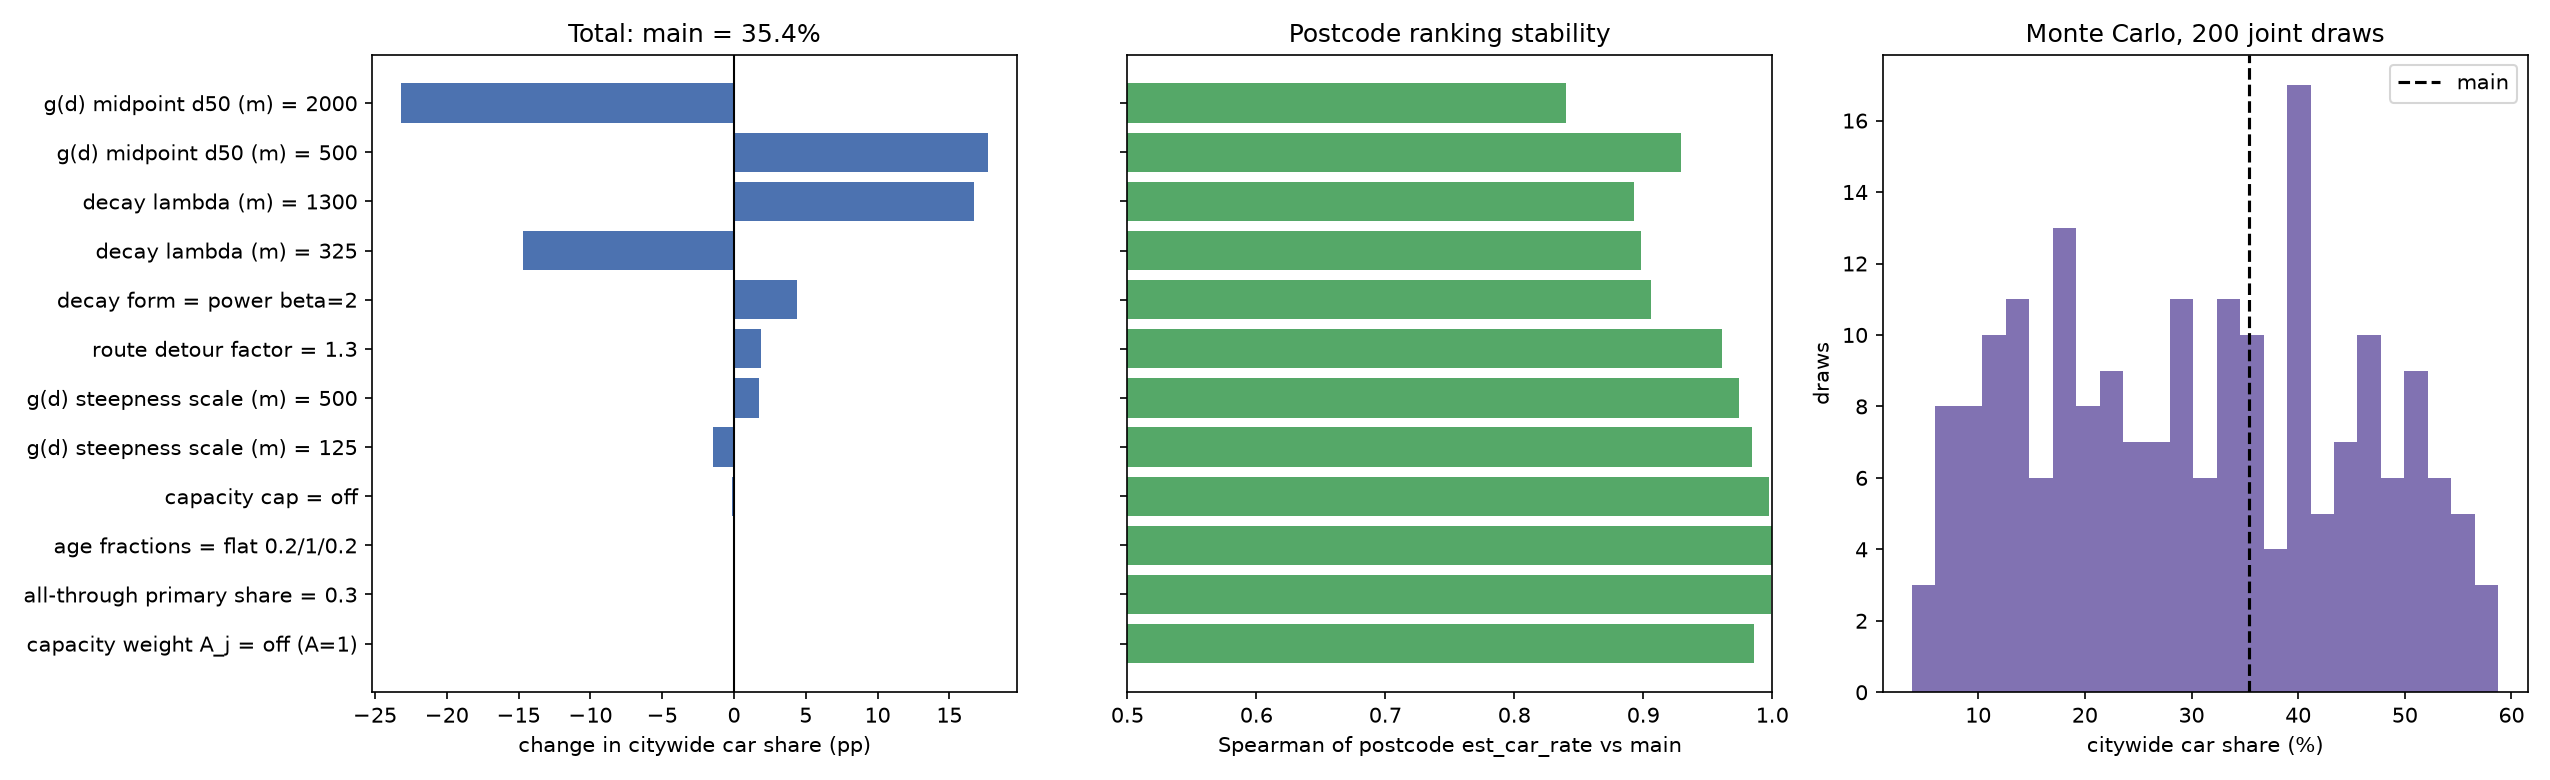

In [12]:
display(Image(FIG / "stage6_sensitivity.png", width=950))

## Stage 7 – Report built from code output

`report/report_draft.md` is filled from `report/report_template.md`. Every number is recomputed from `outputs/` and listed with its source in `outputs/report_numbers.csv`. The Word version is written by `src/export_docx.py`.

In [13]:
run_stage("stage7_report.py", "stage7_log.txt")
run_stage("export_docx.py")
pd.read_csv(OUT / "report_numbers.csv").head(12)

ran stage7_report.py -> outputs/stage7_log.txt


ran export_docx.py


,key,value_in_report,raw_value,source
0,n_postcodes,"20,799",20799,postcodes_master.csv
1,n_oa,"2,606",2606,postcodes_master.csv
2,pc_per_oa_mean,8.0,7.98119723714505,postcodes_master.csv
3,pc_per_oa_max,139,139,postcodes_master.csv
4,total_kids,"68,785",68784.95,postcodes_master.csv
5,inflation_factor,8.0,8.01675366486419,postcodes_master.csv (full OA count per postcode)
6,total_kids_flat,"68,625",68625.0,"agebands by oa.csv, flat 0.2/1/0.2"
7,car_rate_hh,0.713,0.7127501501487259,postcodes_master.csv
8,kids_car_access,"49,467",49467.45096430686,postcodes_master.csv
9,kids_car_access_share,71.9%,0.7191609641979366,postcodes_master.csv


## Quality checks

The test suite covers:

- unique postcode keys with no NaN;
- matching shapes;
- the total of `est_kids` against the school rolls;
- probability rows summing to at most 1;
- hand-checked toy examples;
- that every report number is traced to its source.

In [14]:
r = subprocess.run([sys.executable, "-m", "pytest", "tests", "-q", "--color=no"], cwd=ROOT, capture_output=True, text=True)
print(r.stdout.strip().splitlines()[-1])
assert r.returncode == 0

39 passed in 1.85s
